In [4]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    RocCurveDisplay
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

os.makedirs("week2_outputs", exist_ok=True)

print("Libraries imported successfully.")


Libraries imported successfully.


In [13]:
# Upload the Telco Customer Churn CSV dataset

uploaded = files.upload()

if not uploaded:
    raise ValueError("Please upload the CSV dataset.")

file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("File name:", file_name)
print("Dataset shape:", df.shape)

display(df.head())

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv
Dataset loaded successfully!
File name: WA_Fn-UseC_-Telco-Customer-Churn.csv
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [14]:
# Dataset Information
print("Dataset Information:")
df.info()

# First 5 rows
print("\nFirst 5 Rows:")
display(df.head())

# Statistical Summary
print("\nStatistical Summary:")
display(df.describe(include="all").T)

# Missing Values
print("\nMissing Values:")
print(df.isnull().sum())

# Duplicate Rows
print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  704

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate Rows: 0


In [15]:
# Work on a copy so the original DataFrame remains unchanged
data = df.copy()

# Remove extra spaces from column names
data.columns = data.columns.str.strip()

# Remove extra spaces from text columns
for column in data.select_dtypes(include="object").columns:
    data[column] = data[column].str.strip()

# Convert TotalCharges into numeric values
data["TotalCharges"] = pd.to_numeric(
    data["TotalCharges"], errors="coerce"
)

# Check missing values after conversion
print("Missing values after conversion:")
print(data.isnull().sum())

# Drop duplicate rows from the copy
data = data.drop_duplicates().copy()

print("\nOriginal DataFrame shape:", df.shape)
print("Cleaned DataFrame shape:", data.shape)

print("\nData cleaning completed successfully!")

Missing values after conversion:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Original DataFrame shape: (7043, 21)
Cleaned DataFrame shape: (7043, 21)

Data cleaning completed successfully!


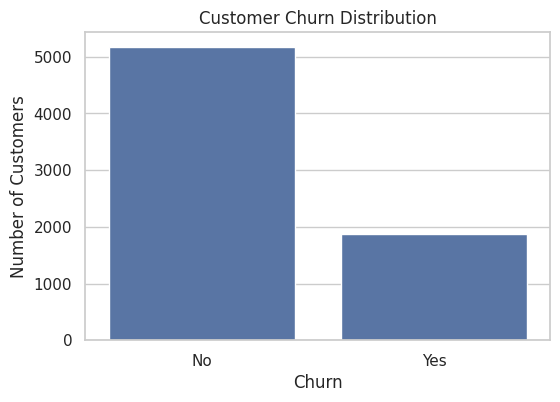

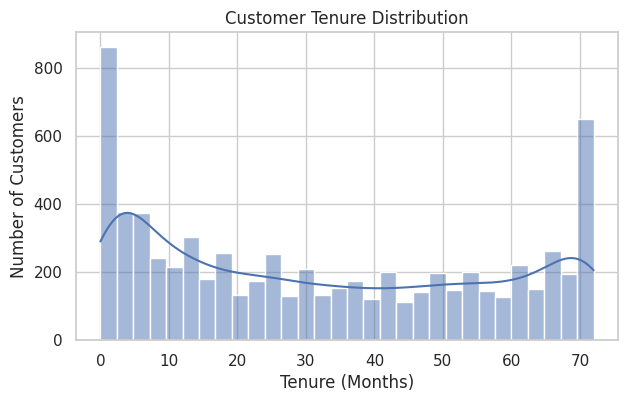

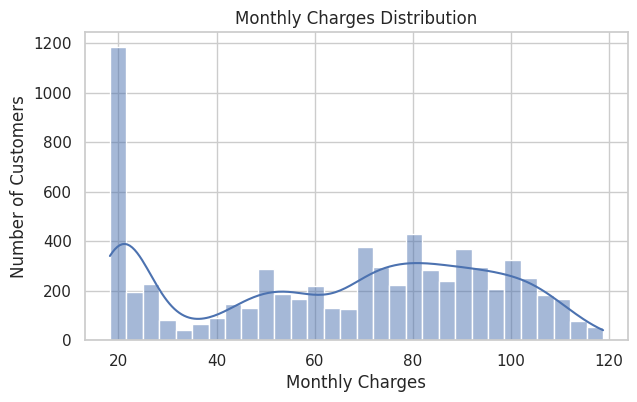

EDA completed successfully!


In [16]:
# 1. Churn Distribution

plt.figure(figsize=(6, 4))

sns.countplot(data=data, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.savefig("week2_outputs/churn_distribution.png")
plt.show()


# 2. Tenure Distribution

plt.figure(figsize=(7, 4))

sns.histplot(data=data, x="tenure", bins=30, kde=True)

plt.title("Customer Tenure Distribution")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.savefig("week2_outputs/tenure_distribution.png")
plt.show()


# 3. Monthly Charges Distribution

plt.figure(figsize=(7, 4))

sns.histplot(data=data, x="MonthlyCharges", bins=30, kde=True)

plt.title("Monthly Charges Distribution")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")

plt.savefig("week2_outputs/monthly_charges_distribution.png")
plt.show()

print("EDA completed successfully!")

In [17]:
# Remove customerID because it is only an identifier
data = data.drop(columns=["customerID"])

# Convert Churn into numerical values
data["Churn"] = data["Churn"].map({
    "No": 0,
    "Yes": 1
})

# Separate features and target
X = data.drop(columns=["Churn"])
y = data["Churn"]

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Features and Target separated successfully!")

print("\nFeatures shape:", X.shape)
print("Target shape:", y.shape)

print("\nNumerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

print("\nTarget Distribution:")
print(y.value_counts())

Features and Target separated successfully!

Features shape: (7043, 19)
Target shape: (7043,)

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Target Distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [18]:
# Split dataset into 80% training and 20% testing

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Dataset split completed successfully!")

print("\nTraining Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

print("\nTraining Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Dataset split completed successfully!

Training Features Shape: (5634, 19)
Testing Features Shape: (1409, 19)

Training Target Shape: (5634,)
Testing Target Shape: (1409,)


In [19]:
# Create preprocessing pipelines for numerical and categorical features

# Numerical features: Handle missing values and scale the data
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical features: Handle missing values and encode the data
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Data preprocessing pipeline created successfully!")

Data preprocessing pipeline created successfully!


In [20]:
# Create Logistic Regression model pipeline
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42,
        class_weight="balanced"
    ))
])

# Create Random Forest model pipeline
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=12,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

# Train Logistic Regression model
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

# Train Random Forest model
random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

print("\nBoth models trained successfully!")

Logistic Regression model trained successfully!
Random Forest model trained successfully!

Both models trained successfully!


In [21]:
# Make predictions using both trained models
logistic_predictions = logistic_model.predict(X_test)
random_forest_predictions = random_forest_model.predict(X_test)

# Evaluate Logistic Regression
logistic_accuracy = accuracy_score(y_test, logistic_predictions)
logistic_precision = precision_score(
    y_test, logistic_predictions, zero_division=0
)
logistic_recall = recall_score(
    y_test, logistic_predictions, zero_division=0
)

# Evaluate Random Forest
rf_accuracy = accuracy_score(y_test, random_forest_predictions)
rf_precision = precision_score(
    y_test, random_forest_predictions, zero_division=0
)
rf_recall = recall_score(
    y_test, random_forest_predictions, zero_division=0
)

# Create model comparison table
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [logistic_accuracy, rf_accuracy],
    "Precision": [logistic_precision, rf_precision],
    "Recall": [logistic_recall, rf_recall]
})

print("MODEL PERFORMANCE COMPARISON")
display(results.round(4))

# Classification reports
print("\nLOGISTIC REGRESSION CLASSIFICATION REPORT")
print(classification_report(
    y_test, logistic_predictions, zero_division=0
))

print("\nRANDOM FOREST CLASSIFICATION REPORT")
print(classification_report(
    y_test, random_forest_predictions, zero_division=0
))

print("\nModel evaluation completed successfully!")

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall
0,Logistic Regression,0.7381,0.5043,0.7834
1,Random Forest,0.7786,0.5721,0.6578



LOGISTIC REGRESSION CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409


RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.87      0.82      0.85      1035
           1       0.57      0.66      0.61       374

    accuracy                           0.78      1409
   macro avg       0.72      0.74      0.73      1409
weighted avg       0.79      0.78      0.78      1409


Model evaluation completed successfully!


<Figure size 900x500 with 0 Axes>

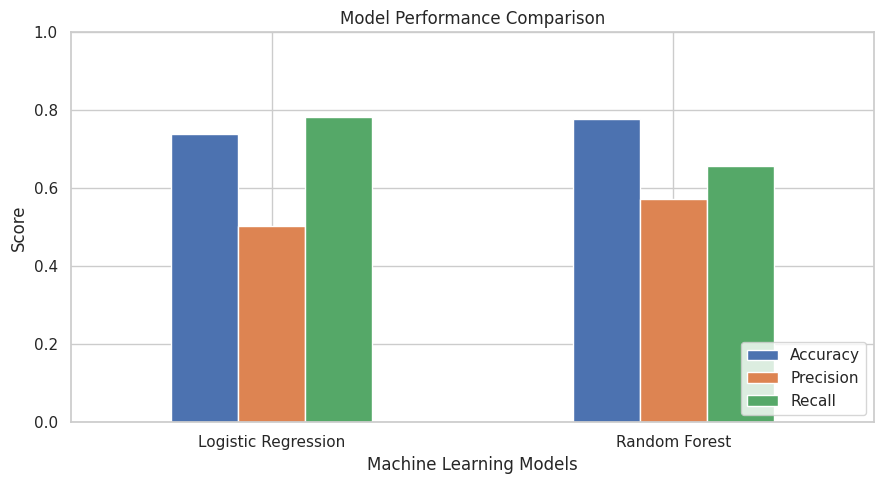

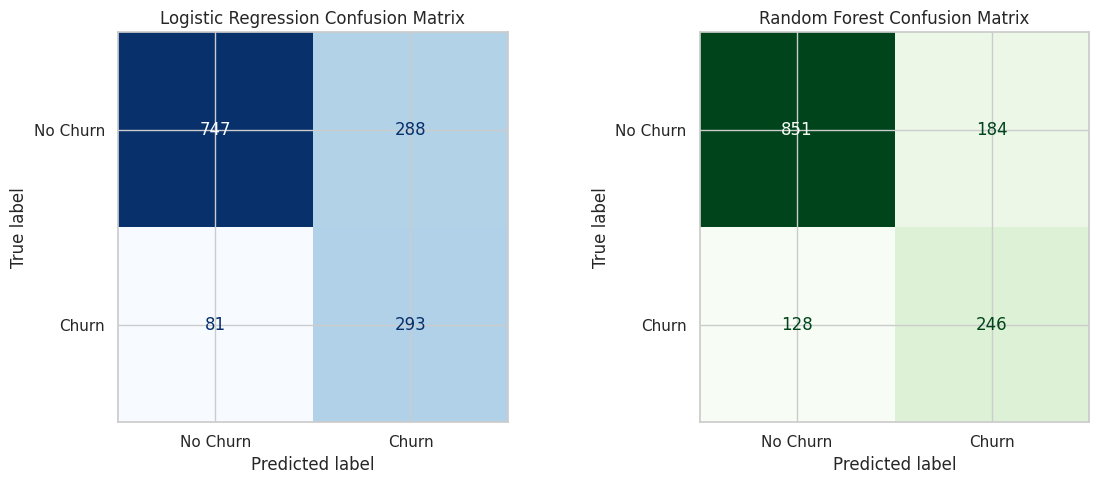

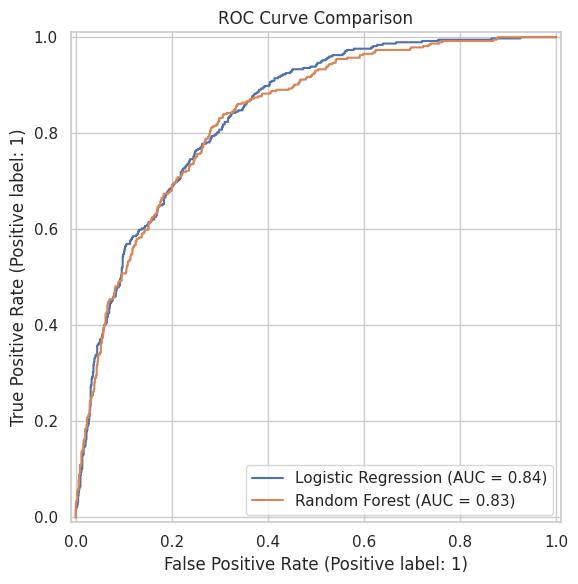

ROC-AUC SCORES
Logistic Regression: 0.8413
Random Forest: 0.8346

All visualizations created successfully!


In [22]:
# STEP 11: MODEL PERFORMANCE VISUALIZATION

# 1. Model Performance Comparison
metrics_df = results.set_index("Model")[
    ["Accuracy", "Precision", "Recall"]
]

plt.figure(figsize=(9, 5))

metrics_df.plot(
    kind="bar",
    figsize=(9, 5),
    ylim=(0, 1),
    rot=0
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Models")
plt.legend(loc="lower right")
plt.tight_layout()

plt.savefig(
    "week2_outputs/model_performance_comparison.png",
    dpi=300
)

plt.show()


# 2. Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    logistic_predictions,
    display_labels=["No Churn", "Churn"],
    cmap="Blues",
    colorbar=False,
    ax=axes[0]
)

axes[0].set_title("Logistic Regression Confusion Matrix")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    random_forest_predictions,
    display_labels=["No Churn", "Churn"],
    cmap="Greens",
    colorbar=False,
    ax=axes[1]
)

axes[1].set_title("Random Forest Confusion Matrix")

plt.tight_layout()

plt.savefig(
    "week2_outputs/confusion_matrices.png",
    dpi=300
)

plt.show()


# 3. ROC Curve
fig, ax = plt.subplots(figsize=(8, 6))

RocCurveDisplay.from_estimator(
    logistic_model,
    X_test,
    y_test,
    name="Logistic Regression",
    ax=ax
)

RocCurveDisplay.from_estimator(
    random_forest_model,
    X_test,
    y_test,
    name="Random Forest",
    ax=ax
)

plt.title("ROC Curve Comparison")
plt.tight_layout()

plt.savefig(
    "week2_outputs/roc_curve_comparison.png",
    dpi=300
)

plt.show()


# Calculate ROC-AUC scores
logistic_auc = roc_auc_score(
    y_test,
    logistic_model.predict_proba(X_test)[:, 1]
)

rf_auc = roc_auc_score(
    y_test,
    random_forest_model.predict_proba(X_test)[:, 1]
)

print("ROC-AUC SCORES")
print("Logistic Regression:", round(logistic_auc, 4))
print("Random Forest:", round(rf_auc, 4))

print("\nAll visualizations created successfully!")